In [1]:
#Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, confusion_matrix, classification_report

In [2]:
#Load the dataset
df = pd.read_csv("/content/WA_Fn-UseC_-Telco-Customer-Churn.csv")

print("First five rows:")
print(df.head())

print("Dataset shape:", df.shape)

First five rows:
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies    

In [3]:
#Basic data exploration
print("Dataset information:")
df.info()

print("\nStatistical summary:")
print(df.describe())

print("\nColumn names:")
print(df.columns)

print("\nTarget value counts:")
print(df["Churn"].value_counts())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  704

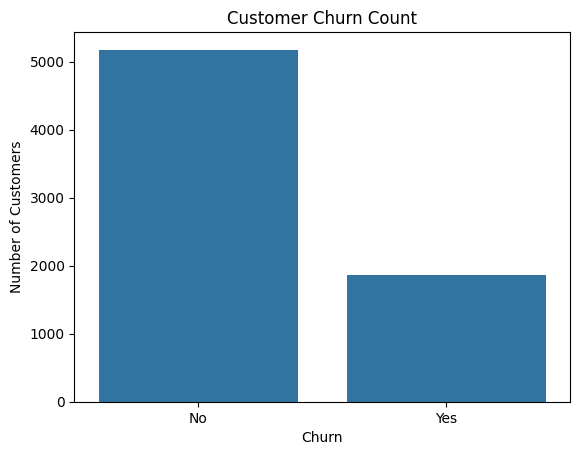

In [4]:
#Visualize the target variable
sns.countplot(x="Churn", data=df)
plt.title("Customer Churn Count")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

In [5]:
#Handle missing values and prepare data
data = df.copy()

data["TotalCharges"] = pd.to_numeric(
    data["TotalCharges"], errors="coerce"
)

print(data.isnull().sum())

data["TotalCharges"] = data["TotalCharges"].fillna(
    data["TotalCharges"].median()
)

data = data.drop("customerID", axis=1)

print(data.isnull().sum())

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [6]:
#Encode categorical variables
data["Churn"] = data["Churn"].map({"No": 0, "Yes": 1})

X = data.drop("Churn", axis=1)
y = data["Churn"]

X = pd.get_dummies(X, drop_first=True)

print(X.head())

   SeniorCitizen  tenure  MonthlyCharges  TotalCharges  gender_Male  \
0              0       1           29.85         29.85        False   
1              0      34           56.95       1889.50         True   
2              0       2           53.85        108.15         True   
3              0      45           42.30       1840.75         True   
4              0       2           70.70        151.65        False   

   Partner_Yes  Dependents_Yes  PhoneService_Yes  \
0         True           False             False   
1        False           False              True   
2        False           False              True   
3        False           False             False   
4        False           False              True   

   MultipleLines_No phone service  MultipleLines_Yes  ...  \
0                            True              False  ...   
1                           False              False  ...   
2                           False              False  ...   
3               

In [7]:
#Split features (X) and target (y)
print(X.shape)
print(y.shape)

(7043, 30)
(7043,)


In [8]:
#Perform Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42)

print(X_train.shape)
print(X_test.shape)

(5634, 30)
(1409, 30)


In [9]:
#Create and train the Random Forest model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

print("Model training completed")

Model training completed


In [10]:
#Make predictions
y_pred = model.predict(X_test)

print("Actual values:")
print(y_test.head(10).values)

print("Predicted values:")
print(y_pred[:10])

Actual values:
[1 0 0 1 0 1 0 0 1 1]
Predicted values:
[1 0 0 1 0 0 0 0 0 0]


In [11]:
#Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

print(classification_report(y_test, y_pred))

Accuracy: 0.7892122072391767
Precision: 0.6428571428571429
Recall: 0.4584450402144772
F1 Score: 0.5352112676056338
Confusion Matrix:
[[941  95]
 [202 171]]
              precision    recall  f1-score   support

           0       0.82      0.91      0.86      1036
           1       0.64      0.46      0.54       373

    accuracy                           0.79      1409
   macro avg       0.73      0.68      0.70      1409
weighted avg       0.78      0.79      0.78      1409



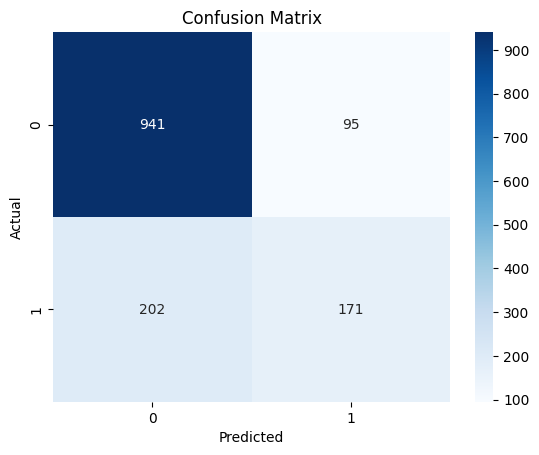

In [12]:
#Confusion matrix visualization
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

Top 10 important features:
TotalCharges                      0.189701
tenure                            0.175710
MonthlyCharges                    0.172418
InternetService_Fiber optic       0.036053
PaymentMethod_Electronic check    0.035302
Contract_Two year                 0.030435
OnlineSecurity_Yes                0.029238
gender_Male                       0.027423
PaperlessBilling_Yes              0.025295
Partner_Yes                       0.024209
dtype: float64


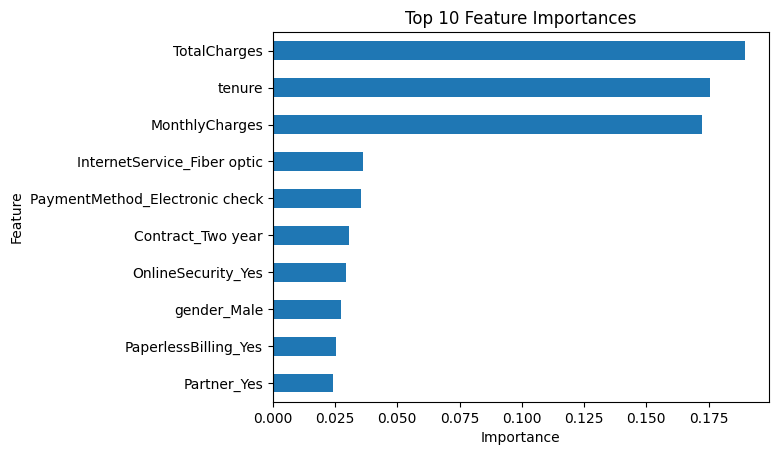

In [13]:
#Feature importance
importance = pd.Series(model.feature_importances_, index=X.columns)
importance = importance.sort_values(ascending=False)

print("Top 10 important features:")
print(importance.head(10))

importance.head(10).sort_values().plot(kind="barh")
plt.title("Top 10 Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

# **Conclusion**

The Random Forest Classifier was trained to predict customer churn using customer details and service information. The dataset was explored, missing TotalCharges values were handled using the median, the customer ID column was removed, and categorical variables were encoded. The data was divided into training and testing sets, and the model was evaluated using Accuracy, Precision, Recall, F1-score and a Confusion Matrix. Feature importance was used to identify the variables that contributed most to the predictions. The results can help a telecom company identify customers who may be at risk of leaving and plan suitable retention activities.

Top 10 Important Features:
TotalCharges                      0.189701
tenure                            0.175710
MonthlyCharges                    0.172418
InternetService_Fiber optic       0.036053
PaymentMethod_Electronic check    0.035302
Contract_Two year                 0.030435
OnlineSecurity_Yes                0.029238
gender_Male                       0.027423
PaperlessBilling_Yes              0.025295
Partner_Yes                       0.024209
dtype: float64


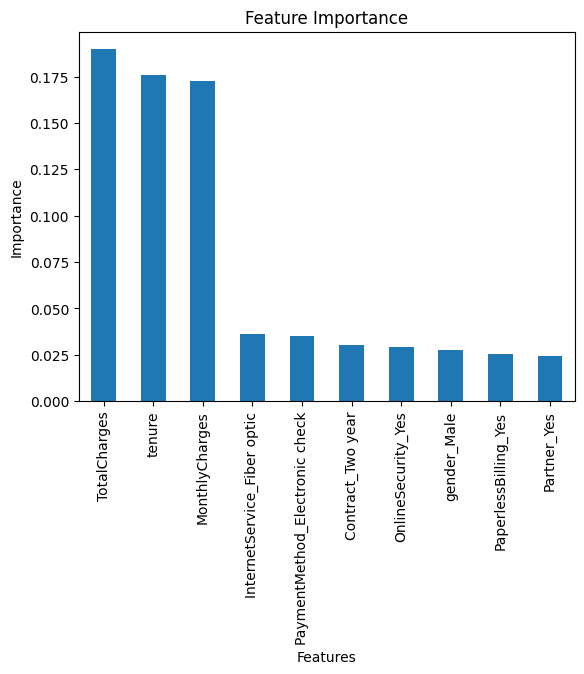

In [14]:
#Feature Importance Visualization
importance = pd.Series(
    model.feature_importances_,
    index=X.columns
)

importance = importance.sort_values(ascending=False)

print("Top 10 Important Features:")
print(importance.head(10))

importance.head(10).plot(kind="bar")

plt.title("Feature Importance")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.xticks(rotation=90)
plt.show()

In [15]:
#Hyperparameter Tuning
from sklearn.model_selection import GridSearchCV

parameters = {
    "n_estimators": [100, 200],
    "max_depth": [10, 20]
}

grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    parameters,
    cv=3,
    scoring="f1"
)

grid.fit(X_train, y_train)

print("Best Parameters:", grid.best_params_)
print("Best Score:", grid.best_score_)

best_model = grid.best_estimator_

y_pred_tuned = best_model.predict(X_test)

print("Tuned Model Accuracy:", accuracy_score(y_test, y_pred_tuned))
print("Tuned Model Precision:", precision_score(y_test, y_pred_tuned))
print("Tuned Model Recall:", recall_score(y_test, y_pred_tuned))
print("Tuned Model F1 Score:", f1_score(y_test, y_pred_tuned))

Best Parameters: {'max_depth': 10, 'n_estimators': 100}
Best Score: 0.5669693521930613
Tuned Model Accuracy: 0.8140525195173882
Tuned Model Precision: 0.697508896797153
Tuned Model Recall: 0.5254691689008043
Tuned Model F1 Score: 0.599388379204893


In [16]:
#Cross Validation
from sklearn.model_selection import cross_val_score

scores = cross_val_score(
    model, X_train, y_train, cv=5
)

print("Cross Validation Scores:", scores)

print("Average Cross Validation Score:", scores.mean())

Cross Validation Scores: [0.80922804 0.79946761 0.7755102  0.78083407 0.78152753]
Average Cross Validation Score: 0.7893134920197131
